
# Assignment: Text Representation Using Bag-of-Words, TF-IDF and Word2Vec

## 1. Introduction

Natural Language Processing (NLP) is a branch of Artificial Intelligence that enables computers to understand, process and analyze human language.

Machine learning algorithms cannot directly understand raw text. Therefore, text must be converted into numerical representations.

In this assignment, we implement and compare three text representation techniques:

1. Bag-of-Words (BoW)
2. Term Frequency-Inverse Document Frequency (TF-IDF)
3. Word2Vec Embeddings

We evaluate these techniques using document similarity and downstream text classification.



## 2. Objectives

- To understand and implement Bag-of-Words representation.
- To implement TF-IDF for measuring the importance of words.
- To generate word embeddings using Word2Vec.
- To calculate document similarity using Cosine Similarity.
- To perform text classification using Logistic Regression.
- To compare the performance of all three techniques.


In [3]:

# Install the required library for Word2Vec

%pip install -q gensim==4.4.0

print("Required package installation completed!")


Required package installation completed!


In [4]:

# ==========================================
# IMPORTING REQUIRED LIBRARIES
# ==========================================

import numpy as np
import pandas as pd
import re
import nltk

# Text Representation
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer

# Similarity Measurement
from sklearn.metrics.pairwise import cosine_similarity

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report

# Word Embeddings
from gensim.models import Word2Vec

print("All libraries imported successfully!")
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)



All libraries imported successfully!
NumPy version: 2.4.6
Pandas version: 2.2.3



## 4. Dataset Preparation

A dataset is a collection of documents used for training and testing machine learning models.

In this experiment, we create a sample text classification dataset containing four categories:

1. Technology
2. Sports
3. Politics
4. Education

Each document contains text related to one of these categories.

The dataset is stored in a Pandas DataFrame with two columns: text and category.


In [5]:

# Create a sample text dataset

data = {
    "text": [
        # Technology
        "Artificial intelligence is transforming modern technology",
        "Machine learning helps computers learn from data",
        "Python programming is useful for software development",
        "Cloud computing provides online storage and services",
        "Data science uses statistics and machine learning",
        "Cybersecurity protects computers from digital attacks",
        "Software engineers develop mobile and web applications",
        "Robotics combines computer science and engineering",
        "Deep learning is used in image recognition",
        "Computer networks connect devices around the world",
        "Artificial intelligence improves automation systems",
        "Developers use programming languages to build software",

        # Sports
        "Cricket is a popular sport played with bat and ball",
        "Football players compete to score goals",
        "The Olympic Games include international sports events",
        "A basketball team scores points by shooting the ball",
        "Athletes practice daily to improve their performance",
        "Tennis players compete using rackets and balls",
        "The cricket team won the championship match",
        "Football tournaments attract millions of fans",
        "Swimming is an important competitive sport",
        "Sports training improves physical fitness",
        "The coach prepared the team for the tournament",
        "Players participate in international cricket competitions",

        # Politics
        "Government policies influence national development",
        "Political parties participate in elections",
        "The parliament discusses important national laws",
        "Democracy allows citizens to elect their leaders",
        "The president represents the country",
        "Election campaigns are conducted by political leaders",
        "The government introduced a new public policy",
        "Citizens vote to select their representatives",
        "Political debates discuss economic development",
        "The minister announced a new government scheme",
        "Parliament members discuss national issues",
        "Elections are important for democratic governance",

        # Education
        "Students attend classes to gain knowledge",
        "Teachers explain concepts to their students",
        "Universities provide higher education programs",
        "Online learning makes education accessible",
        "Students prepare for examinations through practice",
        "Schools organize educational activities",
        "Libraries provide books for academic learning",
        "Teachers evaluate student academic performance",
        "Education develops knowledge and skills",
        "Students complete assignments and projects",
        "Classroom learning improves understanding",
        "Universities offer different academic courses"
    ],

    "category": (
        ["Technology"] * 12 +
        ["Sports"] * 12 +
        ["Politics"] * 12 +
        ["Education"] * 12
    )
}

df = pd.DataFrame(data)

print("Dataset created successfully!")
print("Total documents:", len(df))

display(df.head(10))


Dataset created successfully!
Total documents: 48


,text,category
0,Artificial intelligence is transforming modern...,Technology
1,Machine learning helps computers learn from data,Technology
2,Python programming is useful for software deve...,Technology
3,Cloud computing provides online storage and se...,Technology
4,Data science uses statistics and machine learning,Technology
5,Cybersecurity protects computers from digital ...,Technology
6,Software engineers develop mobile and web appl...,Technology
7,Robotics combines computer science and enginee...,Technology
8,Deep learning is used in image recognition,Technology
9,Computer networks connect devices around the w...,Technology


In [6]:

# Display dataset information

print("Dataset Information:")
print("--------------------")

print("Total documents:", len(df))
print("\nCategory distribution:")
print(df["category"].value_counts())

print("\nMissing values:")
print(df.isnull().sum())


Dataset Information:
--------------------
Total documents: 48

Category distribution:
category
Technology    12
Sports        12
Politics      12
Education     12
Name: count, dtype: int64

Missing values:
text        0
category    0
dtype: int64



## 5. Text Preprocessing

Text preprocessing is the process of cleaning raw text before converting it into numerical representations.

The following operations are performed:

1. Convert text into lowercase.
2. Remove punctuation and special characters.
3. Remove unnecessary extra spaces.
4. Tokenize the text into individual words.

Preprocessing helps maintain consistency and improves the quality of text representation.


In [7]:

# Function to clean text

def preprocess_text(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', '', text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

# Apply preprocessing
df["clean_text"] = df["text"].apply(preprocess_text)

print("Text preprocessing completed!")

display(df[["text", "clean_text", "category"]].head(10))


Text preprocessing completed!


,text,clean_text,category
0,Artificial intelligence is transforming modern...,artificial intelligence is transforming modern...,Technology
1,Machine learning helps computers learn from data,machine learning helps computers learn from data,Technology
2,Python programming is useful for software deve...,python programming is useful for software deve...,Technology
3,Cloud computing provides online storage and se...,cloud computing provides online storage and se...,Technology
4,Data science uses statistics and machine learning,data science uses statistics and machine learning,Technology
5,Cybersecurity protects computers from digital ...,cybersecurity protects computers from digital ...,Technology
6,Software engineers develop mobile and web appl...,software engineers develop mobile and web appl...,Technology
7,Robotics combines computer science and enginee...,robotics combines computer science and enginee...,Technology
8,Deep learning is used in image recognition,deep learning is used in image recognition,Technology
9,Computer networks connect devices around the w...,computer networks connect devices around the w...,Technology


In [8]:

# Tokenize the cleaned text

df["tokens"] = df["clean_text"].apply(lambda text: text.split())

print("Tokenization completed!")

print("\nOriginal sentence:")
print(df["text"][0])

print("\nCleaned sentence:")
print(df["clean_text"][0])

print("\nTokens:")
print(df["tokens"][0])


Tokenization completed!

Original sentence:
Artificial intelligence is transforming modern technology

Cleaned sentence:
artificial intelligence is transforming modern technology

Tokens:
['artificial', 'intelligence', 'is', 'transforming', 'modern', 'technology']



## 6. Bag-of-Words (BoW) Representation

Bag-of-Words is a text representation technique that converts documents into numerical vectors based on the frequency of words.

It creates a vocabulary containing unique words from the dataset.

Each document is represented by counting how many times each vocabulary word appears.

BoW does not consider grammar, word order or semantic meaning.

For example:

Document 1: "machine learning is useful"

Document 2: "machine learning is powerful"

The vocabulary is:

[machine, learning, is, useful, powerful]

Each document is converted into a numerical vector based on word frequency.


In [9]:

# Implement Bag-of-Words

bow_vectorizer = CountVectorizer()

bow_matrix = bow_vectorizer.fit_transform(df["clean_text"])

# Convert into DataFrame
bow_df = pd.DataFrame(
    bow_matrix.toarray(),
    columns=bow_vectorizer.get_feature_names_out()
)

print("Bag-of-Words representation created!")

print("\nVocabulary:")
print(bow_vectorizer.get_feature_names_out())

print("\nBoW Matrix Shape:", bow_matrix.shape)

display(bow_df.head())


Bag-of-Words representation created!

Vocabulary:
['academic' 'accessible' 'activities' 'allows' 'an' 'and' 'announced'
 'applications' 'are' 'around' 'artificial' 'assignments' 'athletes'
 'attacks' 'attend' 'attract' 'automation' 'ball' 'balls' 'basketball'
 'bat' 'books' 'build' 'by' 'campaigns' 'championship' 'citizens'
 'classes' 'classroom' 'cloud' 'coach' 'combines' 'compete' 'competitions'
 'competitive' 'complete' 'computer' 'computers' 'computing' 'concepts'
 'conducted' 'connect' 'country' 'courses' 'cricket' 'cybersecurity'
 'daily' 'data' 'debates' 'deep' 'democracy' 'democratic' 'develop'
 'developers' 'development' 'develops' 'devices' 'different' 'digital'
 'discuss' 'discusses' 'economic' 'education' 'educational' 'elect'
 'election' 'elections' 'engineering' 'engineers' 'evaluate' 'events'
 'examinations' 'explain' 'fans' 'fitness' 'football' 'for' 'from' 'gain'
 'games' 'goals' 'governance' 'government' 'helps' 'higher' 'image'
 'important' 'improve' 'improves' 'in' 

,academic,accessible,activities,allows,an,and,announced,applications,are,around,...,use,used,useful,uses,using,vote,web,with,won,world
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
3,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,1,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0



### Observation – Bag-of-Words

The Bag-of-Words technique successfully converts the text documents into numerical vectors.

Each column represents a unique word, and each row represents a document.

The numerical values indicate the frequency of words in the corresponding document.



## 7. TF-IDF Representation

TF-IDF stands for Term Frequency-Inverse Document Frequency.

It measures the importance of a word in a document compared to the entire collection of documents.

It consists of two components:

**1. Term Frequency (TF)**

Measures how frequently a word appears in a document.

**2. Inverse Document Frequency (IDF)**

Measures how rare or common a word is across all documents.

Formula:

TF-IDF = TF × IDF

Words appearing frequently in a document but rarely across other documents receive higher importance scores.

Unlike Bag-of-Words, TF-IDF assigns importance weights instead of using only word counts.


In [10]:

# Implement TF-IDF

tfidf_vectorizer = TfidfVectorizer()

tfidf_matrix = tfidf_vectorizer.fit_transform(df["clean_text"])

# Convert into DataFrame
tfidf_df = pd.DataFrame(
    tfidf_matrix.toarray(),
    columns=tfidf_vectorizer.get_feature_names_out()
)

print("TF-IDF representation created!")

print("\nTF-IDF Matrix Shape:", tfidf_matrix.shape)

display(tfidf_df.head())


TF-IDF representation created!

TF-IDF Matrix Shape: (48, 191)


,academic,accessible,activities,allows,an,and,announced,applications,are,around,...,use,used,useful,uses,using,vote,web,with,won,world
0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,...,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,...,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,...,0.0,0.0,0.434346,0.000000,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.257161,0.0,0.0,0.0,0.0,...,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.277392,0.0,0.0,0.0,0.0,...,0.0,0.0,0.000000,0.432228,0.0,0.0,0.0,0.0,0.0,0.0


In [11]:

# Display important words and their TF-IDF scores

document_index = 0

tfidf_scores = pd.DataFrame({
    "Word": tfidf_vectorizer.get_feature_names_out(),
    "TF-IDF Score": tfidf_matrix[document_index].toarray().flatten()
})

tfidf_scores = tfidf_scores[
    tfidf_scores["TF-IDF Score"] > 0
].sort_values(by="TF-IDF Score", ascending=False)

print("Important words in Document 1:")

display(tfidf_scores)


Important words in Document 1:


,Word,TF-IDF Score
169,technology,0.439480
111,modern,0.439480
178,transforming,0.439480
10,artificial,0.397039
92,intelligence,0.397039
95,is,0.324487



### Observation – TF-IDF

TF-IDF assigns different weights to words depending on their importance across the document collection.

Words that are more informative receive higher scores, while words appearing in many documents generally receive lower scores.



## 8. Word2Vec Embeddings

Word2Vec is a neural network-based word embedding technique that converts individual words into dense numerical vectors.

Unlike Bag-of-Words and TF-IDF, Word2Vec learns relationships between words based on their surrounding context.

Words that appear in similar contexts can have similar vector representations.

Word2Vec has two main architectures:

1. Continuous Bag-of-Words (CBOW): Predicts a target word using surrounding context words.
2. Skip-gram: Predicts surrounding context words using a target word.

In this experiment, we use the Skip-gram architecture to train a Word2Vec model.

We then calculate document embeddings by taking the average of the word vectors in each document.


In [12]:

# Train Word2Vec model using Skip-gram

sentences = df["tokens"].tolist()

word2vec_model = Word2Vec(
    sentences=sentences,
    vector_size=100,
    window=5,
    min_count=1,
    workers=1,
    sg=1,
    epochs=100,
    seed=42
)

print("Word2Vec model trained successfully!")

print("\nVocabulary size:", len(word2vec_model.wv))
print("Embedding dimension:", word2vec_model.vector_size)


Word2Vec model trained successfully!

Vocabulary size: 192
Embedding dimension: 100


In [13]:

# Display a word embedding

sample_word = "machine"

print("Word:", sample_word)

print("\nWord2Vec Vector:")
print(word2vec_model.wv[sample_word])

print("\nVector Dimension:")
print(len(word2vec_model.wv[sample_word]))


Word: machine

Word2Vec Vector:
[ 1.23449542e-01  1.56283786e-03 -7.15527758e-02  9.84981842e-03
 -1.89404450e-02  1.09016821e-01  1.11108370e-01  1.25194058e-01
 -2.22301781e-01  9.46211591e-02 -2.08248213e-01  6.55560195e-02
  6.75289929e-02  2.26880550e-01  3.25256437e-02 -8.57368633e-02
 -6.71593472e-02 -2.44922608e-01 -1.18877493e-01 -5.19044511e-02
  1.79172888e-01  1.77289635e-01  3.13077308e-02  7.45112300e-02
  1.65625811e-01 -8.22391957e-02 -2.34482601e-01  1.41151562e-01
 -7.81299472e-02 -1.43443763e-01 -1.00118570e-01  3.77748907e-02
  7.61345103e-02  1.87832993e-02 -4.56836894e-02  5.40294871e-03
  1.78445697e-01 -1.36969224e-01  4.49732207e-02  1.25417203e-01
 -1.47995288e-02 -8.58323425e-02  1.05138466e-01 -1.23973876e-01
  8.40797722e-02 -6.39207065e-02  5.37063070e-02  6.83790669e-02
  1.31601244e-01 -6.25276789e-02 -7.41789863e-02 -2.90941119e-01
  8.17760751e-02  2.44064815e-02  4.01704311e-02  4.41785865e-02
  2.75456477e-02  1.19934253e-01 -6.30675480e-02  1.404299

In [14]:

# Find similar words

print("Words similar to 'machine':")

similar_words = word2vec_model.wv.most_similar(
    "machine",
    topn=5
)

for word, score in similar_words:
    print(word, ":", round(score, 4))


Words similar to 'machine':
data : 0.9969
from : 0.9967
uses : 0.9965
computers : 0.9964
and : 0.9961


In [15]:

# Convert word embeddings into document embeddings

def get_document_vector(tokens, model):
    vectors = [
        model.wv[word]
        for word in tokens
        if word in model.wv
    ]

    if len(vectors) == 0:
        return np.zeros(model.vector_size)

    return np.mean(vectors, axis=0)

# Generate document vectors
word2vec_vectors = np.array([
    get_document_vector(tokens, word2vec_model)
    for tokens in df["tokens"]
])

print("Document embeddings created successfully!")

print("Word2Vec Matrix Shape:", word2vec_vectors.shape)


Document embeddings created successfully!
Word2Vec Matrix Shape: (48, 100)



### Observation – Word2Vec

Word2Vec converts words into dense numerical vectors that capture contextual relationships learned during training.

The average of individual word embeddings is used to represent each complete document.

The resulting document vectors can be used for similarity measurement and machine learning classification.



## 9. Document Similarity using Cosine Similarity

Cosine Similarity measures how similar two document vectors are by calculating the cosine of the angle between them.

Its value generally ranges from 0 to 1 for non-negative text representations.

- 1 indicates highly similar vectors.
- 0 indicates no similarity.

Formula:

Cosine Similarity = (A · B) / (||A|| × ||B||)

In this experiment, we calculate document similarity using:

1. Bag-of-Words vectors.
2. TF-IDF vectors.
3. Word2Vec document embeddings.

We select one document from each category and compare their similarity scores.


In [16]:

# Select one document from each category

sample_indices = [0, 12, 24, 36]

sample_labels = df.loc[
    sample_indices, "category"
].tolist()

# Calculate cosine similarity

bow_similarity = cosine_similarity(
    bow_matrix[sample_indices]
)

tfidf_similarity = cosine_similarity(
    tfidf_matrix[sample_indices]
)

word2vec_similarity = cosine_similarity(
    word2vec_vectors[sample_indices]
)

# Convert results into DataFrames

bow_similarity_df = pd.DataFrame(
    bow_similarity,
    index=sample_labels,
    columns=sample_labels
)

tfidf_similarity_df = pd.DataFrame(
    tfidf_similarity,
    index=sample_labels,
    columns=sample_labels
)

word2vec_similarity_df = pd.DataFrame(
    word2vec_similarity,
    index=sample_labels,
    columns=sample_labels
)

print("Bag-of-Words Similarity:")
display(bow_similarity_df.round(3))

print("TF-IDF Similarity:")
display(tfidf_similarity_df.round(3))

print("Word2Vec Similarity:")
display(word2vec_similarity_df.round(3))


Bag-of-Words Similarity:


,Technology,Sports,Politics,Education
Technology,1.000,0.136,0.0,0.0
Sports,0.136,1.000,0.0,0.0
Politics,0.000,0.000,1.0,0.0
Education,0.000,0.000,0.0,1.0


TF-IDF Similarity:


,Technology,Sports,Politics,Education
Technology,1.000,0.089,0.0,0.0
Sports,0.089,1.000,0.0,0.0
Politics,0.000,0.000,1.0,0.0
Education,0.000,0.000,0.0,1.0


Word2Vec Similarity:


,Technology,Sports,Politics,Education
Technology,1.000,0.998,0.998,0.998
Sports,0.998,1.000,0.998,0.999
Politics,0.998,0.998,1.000,0.999
Education,0.998,0.999,0.999,1.000


In [17]:

# Split dataset into training and testing sets

X_train_idx, X_test_idx = train_test_split(
    np.arange(len(df)),
    test_size=0.25,
    random_state=42,
    stratify=df["category"]
)

y_train = df.loc[X_train_idx, "category"]
y_test = df.loc[X_test_idx, "category"]

print("Dataset splitting completed!")

print("Training documents:", len(X_train_idx))
print("Testing documents:", len(X_test_idx))


Dataset splitting completed!
Training documents: 36
Testing documents: 12


In [18]:

# Bag-of-Words classification

bow_classifier_vectorizer = CountVectorizer()

X_train_bow = bow_classifier_vectorizer.fit_transform(
    df.loc[X_train_idx, "clean_text"]
)

X_test_bow = bow_classifier_vectorizer.transform(
    df.loc[X_test_idx, "clean_text"]
)

bow_classifier = LogisticRegression(
    max_iter=1000,
    random_state=42
)

bow_classifier.fit(X_train_bow, y_train)

bow_predictions = bow_classifier.predict(X_test_bow)

bow_accuracy = accuracy_score(
    y_test, bow_predictions
)

print("Bag-of-Words Classification Results")
print("------------------------------------")

print("Accuracy:", round(bow_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, bow_predictions, zero_division=0))


Bag-of-Words Classification Results
------------------------------------
Accuracy: 83.33 %

Classification Report:
              precision    recall  f1-score   support

   Education       0.60      1.00      0.75         3
    Politics       1.00      1.00      1.00         3
      Sports       1.00      0.67      0.80         3
  Technology       1.00      0.67      0.80         3

    accuracy                           0.83        12
   macro avg       0.90      0.83      0.84        12
weighted avg       0.90      0.83      0.84        12



In [19]:

# TF-IDF classification

tfidf_classifier_vectorizer = TfidfVectorizer()

X_train_tfidf = tfidf_classifier_vectorizer.fit_transform(
    df.loc[X_train_idx, "clean_text"]
)

X_test_tfidf = tfidf_classifier_vectorizer.transform(
    df.loc[X_test_idx, "clean_text"]
)

tfidf_classifier = LogisticRegression(
    max_iter=1000,
    random_state=42
)

tfidf_classifier.fit(X_train_tfidf, y_train)

tfidf_predictions = tfidf_classifier.predict(X_test_tfidf)

tfidf_accuracy = accuracy_score(
    y_test, tfidf_predictions
)

print("TF-IDF Classification Results")
print("-----------------------------")

print("Accuracy:", round(tfidf_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, tfidf_predictions, zero_division=0))


TF-IDF Classification Results
-----------------------------
Accuracy: 83.33 %

Classification Report:
              precision    recall  f1-score   support

   Education       0.60      1.00      0.75         3
    Politics       1.00      1.00      1.00         3
      Sports       1.00      0.67      0.80         3
  Technology       1.00      0.67      0.80         3

    accuracy                           0.83        12
   macro avg       0.90      0.83      0.84        12
weighted avg       0.90      0.83      0.84        12



In [20]:

# Train Word2Vec using training documents only

train_tokens = df.loc[X_train_idx, "tokens"].tolist()

classification_w2v_model = Word2Vec(
    sentences=train_tokens,
    vector_size=100,
    window=5,
    min_count=1,
    workers=1,
    sg=1,
    epochs=100,
    seed=42
)

# Generate training and testing document vectors

X_train_w2v = np.array([
    get_document_vector(tokens, classification_w2v_model)
    for tokens in df.loc[X_train_idx, "tokens"]
])

X_test_w2v = np.array([
    get_document_vector(tokens, classification_w2v_model)
    for tokens in df.loc[X_test_idx, "tokens"]
])

# Train Logistic Regression

w2v_classifier = LogisticRegression(
    max_iter=1000,
    random_state=42
)

w2v_classifier.fit(X_train_w2v, y_train)

w2v_predictions = w2v_classifier.predict(X_test_w2v)

w2v_accuracy = accuracy_score(
    y_test, w2v_predictions
)

print("Word2Vec Classification Results")
print("--------------------------------")

print("Accuracy:", round(w2v_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, w2v_predictions, zero_division=0))


Word2Vec Classification Results
--------------------------------
Accuracy: 33.33 %

Classification Report:
              precision    recall  f1-score   support

   Education       0.50      0.67      0.57         3
    Politics       0.00      0.00      0.00         3
      Sports       0.25      0.67      0.36         3
  Technology       0.00      0.00      0.00         3

    accuracy                           0.33        12
   macro avg       0.19      0.33      0.23        12
weighted avg       0.19      0.33      0.23        12



In [21]:

# Compare classification accuracy

comparison_df = pd.DataFrame({
    "Technique": [
        "Bag-of-Words",
        "TF-IDF",
        "Word2Vec"
    ],

    "Accuracy (%)": [
        bow_accuracy * 100,
        tfidf_accuracy * 100,
        w2v_accuracy * 100
    ]
})

comparison_df["Accuracy (%)"] = comparison_df[
    "Accuracy (%)"
].round(2)

print("Classification Performance Comparison")

display(
    comparison_df.sort_values(
        by="Accuracy (%)",
        ascending=False
    ).reset_index(drop=True)
)


Classification Performance Comparison


,Technique,Accuracy (%)
0,Bag-of-Words,83.33
1,TF-IDF,83.33
2,Word2Vec,33.33


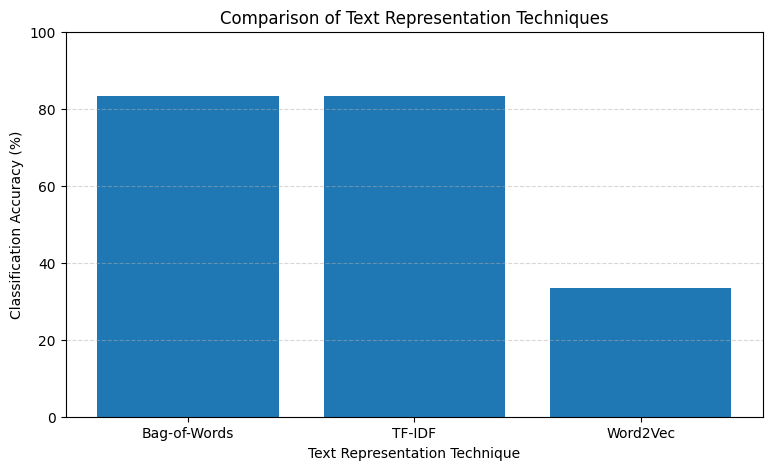

In [22]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    comparison_df["Technique"],
    comparison_df["Accuracy (%)"]
)

plt.title("Comparison of Text Representation Techniques")
plt.xlabel("Text Representation Technique")
plt.ylabel("Classification Accuracy (%)")

plt.ylim(0, 100)

plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.show()


In [23]:

# Final experiment summary

print("=" * 55)
print("FINAL EXPERIMENT RESULTS")
print("=" * 55)

print("\nDataset Information")
print("Total Documents:", len(df))
print("Number of Categories:", df["category"].nunique())

print("\nText Representation")
print("BoW Vocabulary Size:", len(bow_vectorizer.get_feature_names_out()))
print("TF-IDF Vocabulary Size:", len(tfidf_vectorizer.get_feature_names_out()))
print("Word2Vec Embedding Dimension:", word2vec_model.vector_size)

print("\nClassification Accuracy")
print(f"Bag-of-Words: {bow_accuracy * 100:.2f}%")
print(f"TF-IDF:       {tfidf_accuracy * 100:.2f}%")
print(f"Word2Vec:     {w2v_accuracy * 100:.2f}%")

best_method = comparison_df.loc[
    comparison_df["Accuracy (%)"].idxmax(),
    "Technique"
]

print("\nBest Performing Technique:", best_method)

print("\n" + "=" * 55)
print("EXPERIMENT COMPLETED SUCCESSFULLY!")
print("=" * 55)


FINAL EXPERIMENT RESULTS

Dataset Information
Total Documents: 48
Number of Categories: 4

Text Representation
BoW Vocabulary Size: 191
TF-IDF Vocabulary Size: 191
Word2Vec Embedding Dimension: 100

Classification Accuracy
Bag-of-Words: 83.33%
TF-IDF:       83.33%
Word2Vec:     33.33%

Best Performing Technique: Bag-of-Words

EXPERIMENT COMPLETED SUCCESSFULLY!



## 12. Conclusion

In this experiment, three popular NLP text representation techniques, namely Bag-of-Words, TF-IDF and Word2Vec, were implemented using Python.

Bag-of-Words converted text into numerical vectors based on word frequency.

TF-IDF assigned importance scores to words based on their frequency within a document and across the document collection.

Word2Vec generated dense word embeddings that learned contextual relationships between words.

Cosine Similarity was used to compare document representations, while Logistic Regression was used for downstream text classification.

The classification accuracy of all three techniques was evaluated and compared.

The experiment demonstrates that different text representation techniques have different characteristics and applications in Natural Language Processing.

Thus, text representation plays an important role in improving the performance of machine learning and NLP applications.
